In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


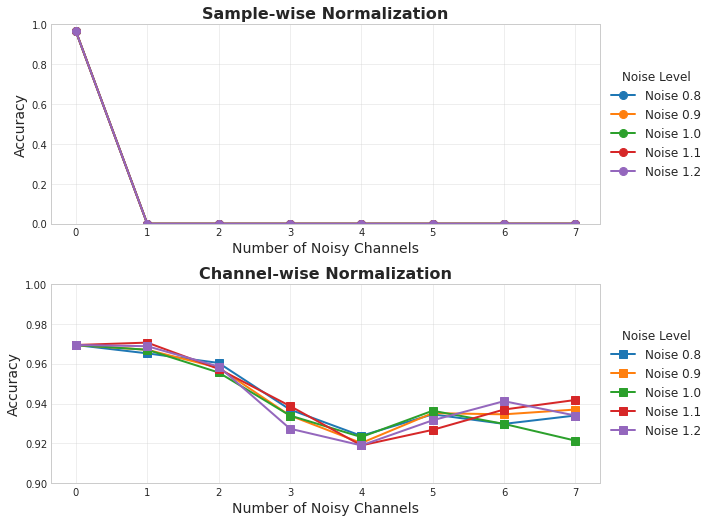

In [2]:
exp=1
# with votting ==5
# Leitura dos CSVs
sample_df = pd.read_csv(f"trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW_experiment_{exp}.csv")
channel_df = pd.read_csv(f"trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_adamW_experiment_{exp}.csv")

# Adiciona info da normalização
sample_df["normalization"] = "Sample-wise"
channel_df["normalization"] = "Channel-wise"

# Junta os dados
df = pd.concat([sample_df, channel_df], ignore_index=True)

# Renomeia colunas pra facilitar (opcional)
df.rename(columns={
    "max_noise_amplitude": "noise",
    "num_noisy_channels": "noisy_channels"
}, inplace=True)
import matplotlib.pyplot as plt

# Paleta padrão tab10 do Matplotlib
palette = plt.get_cmap('tab10')

plt.style.use('seaborn-whitegrid')
font_size = 14
title_size = 16
legend_fontsize = 12
marker_size = 8
line_width = 2

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharey=False)

# Sample-wise normalization
noise_levels_sample = sorted(df[df["normalization"] == "Sample-wise"]["noise"].unique())
for i, noise_level in enumerate(noise_levels_sample):
    subset = df[(df["normalization"] == "Sample-wise") & (df["noise"] == noise_level)]
    axes[0].plot(subset["noisy_channels"], subset["accuracy"], 
                 marker='o', linestyle='-', color=palette(i), 
                 label=f"Noise {noise_level}", linewidth=line_width, markersize=marker_size)

axes[0].set_title("Sample-wise Normalization", fontsize=title_size, fontweight='bold')
axes[0].set_xlabel("Number of Noisy Channels", fontsize=font_size)
axes[0].set_ylabel("Accuracy", fontsize=font_size)
axes[0].set_ylim(0, 1)
axes[0].grid(alpha=0.4)
axes[0].legend(title="Noise Level", fontsize=legend_fontsize, title_fontsize=legend_fontsize)

# Channel-wise normalization
noise_levels_channel = sorted(df[df["normalization"] == "Channel-wise"]["noise"].unique())
for i, noise_level in enumerate(noise_levels_channel):
    subset = df[(df["normalization"] == "Channel-wise") & (df["noise"] == noise_level)]
    axes[1].plot(subset["noisy_channels"], subset["accuracy"], 
                 marker='s', linestyle='-', color=palette(i), 
                 label=f"Noise {noise_level}", linewidth=line_width, markersize=marker_size)

axes[1].set_title("Channel-wise Normalization", fontsize=title_size, fontweight='bold')
axes[1].set_xlabel("Number of Noisy Channels", fontsize=font_size)
axes[1].set_ylabel("Accuracy", fontsize=font_size)
axes[1].set_ylim(0.9, 1)
axes[1].grid(alpha=0.4)
axes[1].legend(title="Noise Level", fontsize=legend_fontsize, title_fontsize=legend_fontsize)


axes[0].set_xlabel("Number of Noisy Channels", fontsize=font_size)
axes[0].set_ylabel("Accuracy", fontsize=font_size)
axes[1].set_xlabel("Number of Noisy Channels", fontsize=font_size)
axes[1].set_ylabel("Accuracy", fontsize=font_size)

axes[0].legend(title="Noise Level", fontsize=legend_fontsize, title_fontsize=legend_fontsize,
               loc='center left', bbox_to_anchor=(1, 0.5))

axes[1].legend(title="Noise Level", fontsize=legend_fontsize, title_fontsize=legend_fontsize,
               loc='center left', bbox_to_anchor=(1, 0.5))
#plt.suptitle("Accuracy vs. Number of Noisy Channels\nby Noise Level and Normalization Method", 
#             fontsize=18, fontweight='bold')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


### Increase the N of channels with noise 

In [3]:

exp=2
# Leitura dos CSVs
sample_df = pd.read_csv(f"trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW_experiment_{exp}.csv")
channel_df = pd.read_csv(f"trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_adamW_experiment_{exp}.csv")

# Adiciona info da normalização
sample_df["normalization"] = "Sample-wise"
channel_df["normalization"] = "Channel-wise"

# Junta os dados
df = pd.concat([sample_df, channel_df], ignore_index=True)

# Renomeia colunas pra facilitar (opcional)
df.rename(columns={
    "max_noise_amplitude": "noise",
    "num_noisy_channels": "noisy_channels"
}, inplace=True)

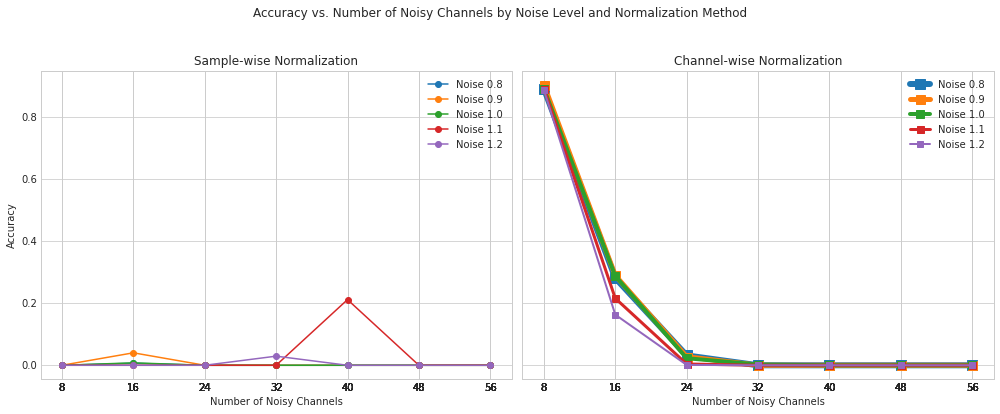

In [4]:
# Create subplots for each normalization method
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Plot Sample-wise normalization
for noise_level in sorted(df[df["normalization"] == "Sample-wise"]["noise"].unique()):
    subset = df[(df["normalization"] == "Sample-wise") & (df["noise"] == noise_level)]
    axes[0].plot(subset["noisy_channels"], subset["accuracy"], marker='o', label=f"Noise {noise_level}")

axes[0].set_xticks(df["noisy_channels"])  # Ensure actual values are shown on x-axis
axes[0].set_title("Sample-wise Normalization")
axes[0].set_xlabel("Number of Noisy Channels")
axes[0].set_ylabel("Accuracy")

plt.xticks(df["noisy_channels"])  # Ensure actual values are shown on x-axis
axes[0].grid(True)
axes[0].legend()

# Plot Channel-wise normalization
for idx, noise_level in enumerate(sorted(df[df["normalization"] == "Channel-wise"]["noise"].unique())):
    subset = df[(df["normalization"] == "Channel-wise") & (df["noise"] == noise_level)]
    axes[1].plot(subset["noisy_channels"], subset["accuracy"], marker='s', label=f"Noise {noise_level}", markersize=10-idx, linewidth=6-idx )
    
axes[1].set_xticks(df["noisy_channels"])  # Ensure actual values are shown on x-axis
axes[1].set_title("Channel-wise Normalization")
axes[1].set_xlabel("Number of Noisy Channels")
axes[1].grid(True)
axes[1].legend()

plt.suptitle("Accuracy vs. Number of Noisy Channels by Noise Level and Normalization Method")
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()



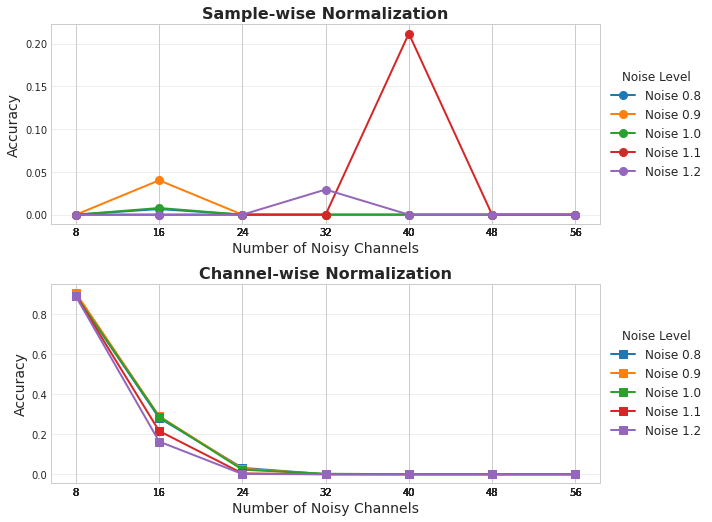

In [5]:
# Paleta padrão tab10 do Matplotlib
palette = plt.get_cmap('tab10')

plt.style.use('seaborn-whitegrid')
font_size = 14
title_size = 16
legend_fontsize = 12
marker_size = 8
line_width = 2

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharey=False)

# Sample-wise normalization
noise_levels_sample = sorted(df[df["normalization"] == "Sample-wise"]["noise"].unique())
for i, noise_level in enumerate(noise_levels_sample):
    subset = df[(df["normalization"] == "Sample-wise") & (df["noise"] == noise_level)]
    axes[0].plot(subset["noisy_channels"], subset["accuracy"], 
                 marker='o', linestyle='-', color=palette(i), 
                 label=f"Noise {noise_level}", linewidth=line_width, markersize=marker_size)

axes[0].set_title("Sample-wise Normalization", fontsize=title_size, fontweight='bold')
axes[0].set_xlabel("Number of Noisy Channels", fontsize=font_size)
axes[0].set_ylabel("Accuracy", fontsize=font_size)
#axes[0].set_ylim(0, 1)
axes[0].grid(alpha=0.4)
axes[0].legend(title="Noise Level", fontsize=legend_fontsize, title_fontsize=legend_fontsize)

# Channel-wise normalization
noise_levels_channel = sorted(df[df["normalization"] == "Channel-wise"]["noise"].unique())
for i, noise_level in enumerate(noise_levels_channel):
    subset = df[(df["normalization"] == "Channel-wise") & (df["noise"] == noise_level)]
    axes[1].plot(subset["noisy_channels"], subset["accuracy"], 
                 marker='s', linestyle='-', color=palette(i), 
                 label=f"Noise {noise_level}", linewidth=line_width, markersize=marker_size)
axes[1].set_xticks(df["noisy_channels"])  # Ensure actual values are shown on x-axis

axes[1].set_title("Channel-wise Normalization", fontsize=title_size, fontweight='bold')
axes[1].set_xlabel("Number of Noisy Channels", fontsize=font_size)
axes[1].set_ylabel("Accuracy", fontsize=font_size)
#axes[1].set_ylim(0.9, 1)
axes[1].grid(alpha=0.4)
axes[1].legend(title="Noise Level", fontsize=legend_fontsize, title_fontsize=legend_fontsize)

axes[0].set_xticks(df["noisy_channels"])  # Ensure actual values are shown on x-axis
axes[0].set_xlabel("Number of Noisy Channels", fontsize=font_size)
axes[0].set_ylabel("Accuracy", fontsize=font_size)
axes[1].set_xlabel("Number of Noisy Channels", fontsize=font_size)
axes[1].set_ylabel("Accuracy", fontsize=font_size)

axes[0].legend(title="Noise Level", fontsize=legend_fontsize, title_fontsize=legend_fontsize,
               loc='center left', bbox_to_anchor=(1, 0.5))

axes[1].legend(title="Noise Level", fontsize=legend_fontsize, title_fontsize=legend_fontsize,
               loc='center left', bbox_to_anchor=(1, 0.5))
#plt.suptitle("Accuracy vs. Number of Noisy Channels\nby Noise Level and Normalization Method", 
#             fontsize=18, fontweight='bold')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

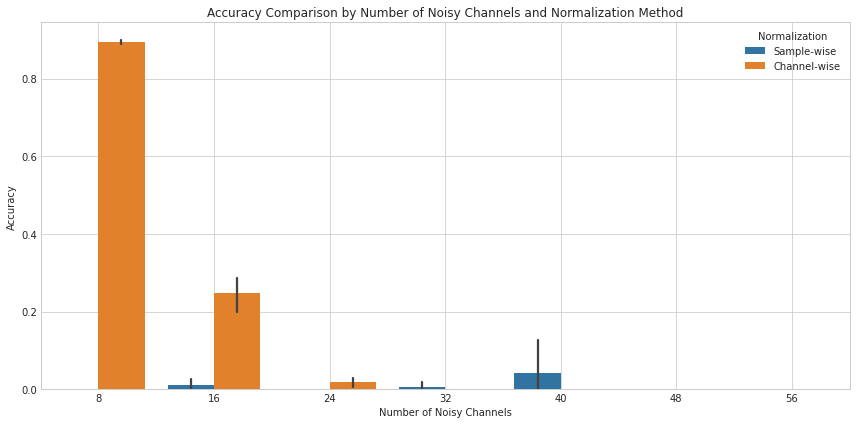

In [6]:

# Create grouped bar plot
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x="noisy_channels", y="accuracy", hue="normalization")

plt.title("Accuracy Comparison by Number of Noisy Channels and Normalization Method")
plt.xlabel("Number of Noisy Channels")
plt.ylabel("Accuracy")
plt.legend(title="Normalization")
plt.grid(True)
plt.tight_layout()
plt.show()


### Faulty sensors

In [7]:

exp=3
# Leitura dos CSVs
sample_df = pd.read_csv(f"trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW_experiment_{exp}.csv")
channel_df = pd.read_csv(f"trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_adamW_experiment_{exp}.csv")

# Adiciona info da normalização
sample_df["normalization"] = "Sample-wise"
channel_df["normalization"] = "Channel-wise"

# Junta os dados
df = pd.concat([sample_df, channel_df], ignore_index=True)

# Renomeia colunas pra facilitar (opcional)
df.rename(columns={
    "max_noise_amplitude": "noise",
    "num_noisy_channels": "noisy_channels"
}, inplace=True)

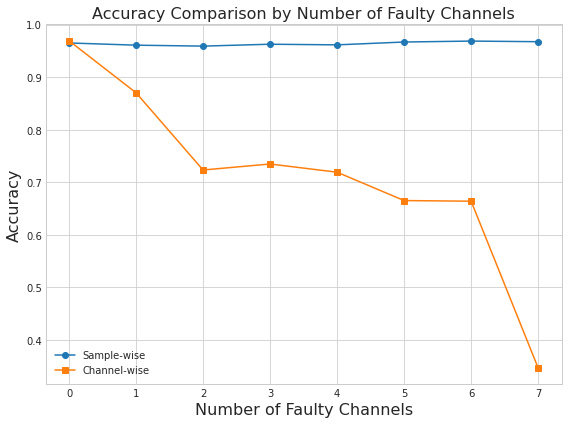

In [8]:

# Separate data by normalization method
sample_df = df[df["normalization"] == "Sample-wise"]
channel_df = df[df["normalization"] == "Channel-wise"]

#sample_df = df[df["normalization"] == "Channel-wise"]
#channel_df = df[df["normalization"] == "Sample-wise"]

# Plot the data
plt.figure(figsize=(8, 6))
plt.plot(sample_df["num_fault_channels"], sample_df["accuracy"], marker='o', label="Sample-wise")
plt.plot(channel_df["num_fault_channels"], channel_df["accuracy"], marker='s', label="Channel-wise")

plt.title("Accuracy Comparison by Number of Faulty Channels",fontsize=16)
plt.xlabel("Number of Faulty Channels", fontsize=16)
plt.ylabel("Accuracy", fontsize=16)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



### Noise X n channels using votte==5

In [9]:
exp=4
# with votting ==5
# Leitura dos CSVs
sample_df = pd.read_csv(f"trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW_experiment_{exp}.csv")
channel_df = pd.read_csv(f"trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_adamW_experiment_{exp}.csv")

# Adiciona info da normalização
sample_df["normalization"] = "Sample-wise"
channel_df["normalization"] = "Channel-wise"

# Junta os dados
df = pd.concat([sample_df, channel_df], ignore_index=True)

# Renomeia colunas pra facilitar (opcional)
df.rename(columns={
    "max_noise_amplitude": "noise",
    "num_noisy_channels": "noisy_channels"
}, inplace=True)


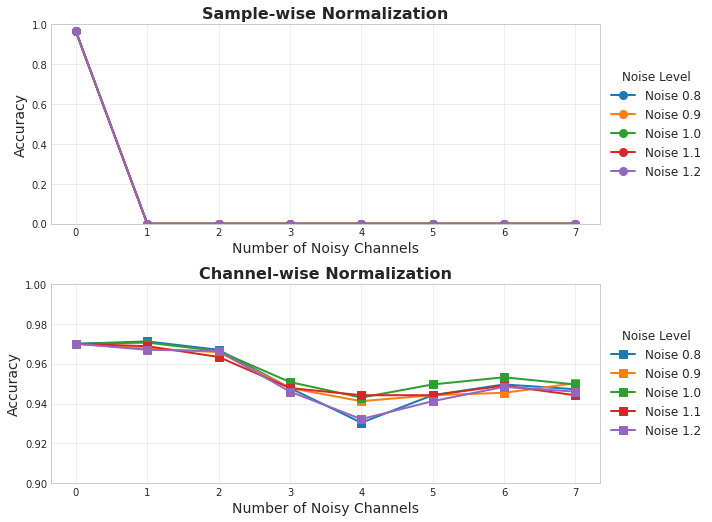

In [10]:
import matplotlib.pyplot as plt

# Paleta padrão tab10 do Matplotlib
palette = plt.get_cmap('tab10')

plt.style.use('seaborn-whitegrid')
font_size = 14
title_size = 16
legend_fontsize = 12
marker_size = 8
line_width = 2

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharey=False)

# Sample-wise normalization
noise_levels_sample = sorted(df[df["normalization"] == "Sample-wise"]["noise"].unique())
for i, noise_level in enumerate(noise_levels_sample):
    subset = df[(df["normalization"] == "Sample-wise") & (df["noise"] == noise_level)]
    axes[0].plot(subset["noisy_channels"], subset["accuracy"], 
                 marker='o', linestyle='-', color=palette(i), 
                 label=f"Noise {noise_level}", linewidth=line_width, markersize=marker_size)

axes[0].set_title("Sample-wise Normalization", fontsize=title_size, fontweight='bold')
axes[0].set_xlabel("Number of Noisy Channels", fontsize=font_size)
axes[0].set_ylabel("Accuracy", fontsize=font_size)
axes[0].set_ylim(0, 1)
axes[0].grid(alpha=0.4)
axes[0].legend(title="Noise Level", fontsize=legend_fontsize, title_fontsize=legend_fontsize)

# Channel-wise normalization
noise_levels_channel = sorted(df[df["normalization"] == "Channel-wise"]["noise"].unique())
for i, noise_level in enumerate(noise_levels_channel):
    subset = df[(df["normalization"] == "Channel-wise") & (df["noise"] == noise_level)]
    axes[1].plot(subset["noisy_channels"], subset["accuracy"], 
                 marker='s', linestyle='-', color=palette(i), 
                 label=f"Noise {noise_level}", linewidth=line_width, markersize=marker_size)

axes[1].set_title("Channel-wise Normalization", fontsize=title_size, fontweight='bold')
axes[1].set_xlabel("Number of Noisy Channels", fontsize=font_size)
axes[1].set_ylabel("Accuracy", fontsize=font_size)
axes[1].set_ylim(0.9, 1)
axes[1].grid(alpha=0.4)
axes[1].legend(title="Noise Level", fontsize=legend_fontsize, title_fontsize=legend_fontsize)


axes[0].set_xlabel("Number of Noisy Channels", fontsize=font_size)
axes[0].set_ylabel("Accuracy", fontsize=font_size)
axes[1].set_xlabel("Number of Noisy Channels", fontsize=font_size)
axes[1].set_ylabel("Accuracy", fontsize=font_size)

axes[0].legend(title="Noise Level", fontsize=legend_fontsize, title_fontsize=legend_fontsize,
               loc='center left', bbox_to_anchor=(1, 0.5))

axes[1].legend(title="Noise Level", fontsize=legend_fontsize, title_fontsize=legend_fontsize,
               loc='center left', bbox_to_anchor=(1, 0.5))
#plt.suptitle("Accuracy vs. Number of Noisy Channels\nby Noise Level and Normalization Method", 
#             fontsize=18, fontweight='bold')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


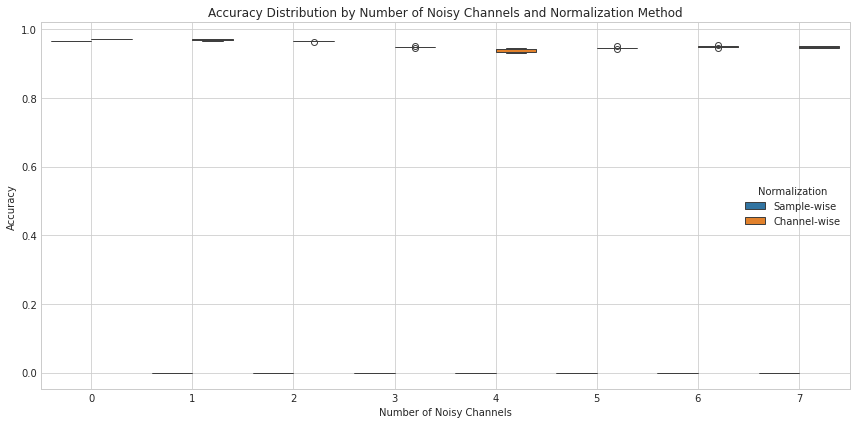

In [11]:
# Create boxplot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="noisy_channels", y="accuracy", hue="normalization")

plt.title("Accuracy Distribution by Number of Noisy Channels and Normalization Method")
plt.xlabel("Number of Noisy Channels")
plt.ylabel("Accuracy")
plt.legend(title="Normalization")
plt.grid(True)
plt.tight_layout()
plt.show()



In [12]:
# Group by noisy_channels and normalization, then compute mean and std of accuracy
summary = df.groupby(["noisy_channels", "normalization"])["accuracy"].agg(["mean", "std"]).reset_index()

# Rename columns for clarity
summary.columns = ["Noisy Channels", "Normalization", "Mean Accuracy", "Std Accuracy"]
# Supondo que summary já esteja carregado conforme você mostrou:
summary["Formatted"] = summary["Mean Accuracy"].map(lambda x: f"{x*100:.2f}") + " ± " + summary["Std Accuracy"].map(lambda x: f"{x*100:.2f}")

# Pivot table
formatted_summary = summary.pivot(index="Noisy Channels", columns="Normalization", values="Formatted")
formatted_summary.columns.name = None
formatted_summary = formatted_summary.rename(columns={
    "Channel-wise": "Channel-wise normalization",
    "Sample-wise": "Sample-wise normalization"
})
formatted_summary = formatted_summary.reset_index()

# Exportar para LaTeX
latex_table = formatted_summary.to_latex(index=False, column_format='c|c|c', escape=False)
print(latex_table)

\begin{tabular}{c|c|c}
\toprule
 Noisy Channels & Channel-wise normalization & Sample-wise normalization \\
\midrule
              0 &               97.00 ± 0.00 &              96.52 ± 0.00 \\
              1 &               96.90 ± 0.18 &               0.00 ± 0.00 \\
              2 &               96.58 ± 0.14 &               0.00 ± 0.00 \\
              3 &               94.81 ± 0.17 &               0.00 ± 0.00 \\
              4 &               93.82 ± 0.64 &               0.00 ± 0.00 \\
              5 &               94.47 ± 0.30 &               0.00 ± 0.00 \\
              6 &               94.91 ± 0.28 &               0.00 ± 0.00 \\
              7 &               94.75 ± 0.25 &               0.00 ± 0.00 \\
\bottomrule
\end{tabular}



In [13]:

# Agrupamento por número de canais ruidosos e método
summary = df.groupby(["noisy_channels", "normalization"])["accuracy"].agg(["mean", "std"]).reset_index()
summary.columns = ["Noisy Channels", "Normalization", "Mean Accuracy", "Std Accuracy"]

# Geração da tabela LaTeX
latex_table = "\\begin{table}[ht]\n\\centering\n\\begin{tabular}{|c|c|c|c|}\n\\hline\n"
latex_table += "\\textbf{Noisy Channels} & \\textbf{Normalization} & \\textbf{Mean Accuracy} & \\textbf{Std Accuracy} \\\\\n\\hline\n"

for _, row in summary.iterrows():
    latex_table += f"{int(row['Noisy Channels'])} & {row['Normalization']} & {row['Mean Accuracy']:.6f} & {row['Std Accuracy']:.6f} \\\\\n"

latex_table += "\\hline\n\\end{tabular}\n"
latex_table += "\\caption{Mean and Standard Deviation of Accuracy by Number of Noisy Channels and Normalization Method}\n"
latex_table += "\\label{tab:accuracy_summary}\n\\end{table}"

print(latex_table)


\begin{table}[ht]
\centering
\begin{tabular}{|c|c|c|c|}
\hline
\textbf{Noisy Channels} & \textbf{Normalization} & \textbf{Mean Accuracy} & \textbf{Std Accuracy} \\
\hline
0 & Channel-wise & 0.970006 & 0.000000 \\
0 & Sample-wise & 0.965207 & 0.000000 \\
1 & Channel-wise & 0.969046 & 0.001829 \\
1 & Sample-wise & 0.000000 & 0.000000 \\
2 & Channel-wise & 0.965807 & 0.001407 \\
2 & Sample-wise & 0.000000 & 0.000000 \\
3 & Channel-wise & 0.948050 & 0.001728 \\
3 & Sample-wise & 0.000000 & 0.000000 \\
4 & Channel-wise & 0.938212 & 0.006419 \\
4 & Sample-wise & 0.000000 & 0.000000 \\
5 & Channel-wise & 0.944691 & 0.003041 \\
5 & Sample-wise & 0.000000 & 0.000000 \\
6 & Channel-wise & 0.949130 & 0.002794 \\
6 & Sample-wise & 0.000000 & 0.000000 \\
7 & Channel-wise & 0.947451 & 0.002495 \\
7 & Sample-wise & 0.000000 & 0.000000 \\
\hline
\end{tabular}
\caption{Mean and Standard Deviation of Accuracy by Number of Noisy Channels and Normalization Method}
\label{tab:accuracy_summary}
\end{table}
